In [1]:
import sys
import json
import hashlib
import platform
import time
from pathlib import Path
from collections import Counter
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BENIH = 1
MODE_KORPUS = "praktis"  # Pilihan: "praktis" atau "penuh".
assert MODE_KORPUS in {"praktis", "penuh"}, "Mode korpus tidak dikenali."

DIMENSI_SENTIMEN = 100
LAJU_SENTIMEN = 0.01
PUTARAN_SENTIMEN = 2
DIMENSI_KONTEKS = 50
LAJU_KONTEKS = 0.05
PUTARAN_KONTEKS = 2
JENDELA = 2
JUMLAH_NEGATIF = 5
BATAS_ULASAN_KONTEKS = 3000 if MODE_KORPUS == "praktis" else None
BATAS_KATA_KONTEKS = 120 if MODE_KORPUS == "praktis" else None

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Versi Python:", platform.python_version())
print("Versi NumPy:", np.__version__)
print("Mode korpus konteks:", MODE_KORPUS)
print("Model inti: NumPy; tidak memerlukan GPU.")

Versi Python: 3.13.16
Versi NumPy: 2.1.3
Mode korpus konteks: praktis
Model inti: NumPy; tidak memerlukan GPU.


## 3. Landasan teori: apa yang dimaksud memahami bahasa?

Pemrosesan bahasa alami adalah bidang yang mengolah bahasa manusia secara komputasional. Keberhasilan pada satu tugas tidak berarti model memahami semua aspek bahasa. Model sentimen, misalnya, dapat mengenali kata yang berkorelasi dengan penilaian positif tanpa mampu menjelaskan ironi atau alur cerita.

Bab ini mengelompokkan tugas bahasa menjadi pemberian label pada teks, pengaitan beberapa bagian teks, dan pengisian informasi yang hilang. Contohnya adalah penandaan kelas kata, pengenalan nama orang atau tempat, penentuan apakah dua kata ganti merujuk pada orang yang sama, serta analisis sentimen.

Dalam pembelajaran terawasi, tersedia pasangan masukan dan target. Untuk ulasan, masukannya adalah teks dan targetnya adalah label positif atau negatif. Karena jaringan saraf bekerja pada angka, teks harus diubah menjadi representasi numerik. Pilihan representasi menentukan informasi apa yang tersedia bagi model dan informasi apa yang hilang sebelum pelatihan dimulai.

## 4. Memuat korpus ulasan IMDB

Distribusi IMDB yang umum mencakup 50.000 ulasan berlabel, tetapi berkas pendamping buku yang digunakan di sini berisi **25.000 ulasan** dan 25.000 label biner. Notebook memakai label `positive`/`negative` yang benar-benar tersedia dalam berkas, bukan mengonversi angka bintang yang tidak ada di berkas ini. Label positif dikodekan sebagai 1 dan negatif sebagai 0.

Unduhan berasal dari repositori resmi penulis. Pemeriksaan SHA-256 memastikan isi berkas sama dengan data yang digunakan saat notebook disiapkan. Jika sumber berubah atau berkas lokal keliru, kode berhenti dengan pesan yang menjelaskan masalahnya, bukan diam-diam menggunakan data lain.

In [2]:
FOLDER_DATA = Path("data_bab11")
FOLDER_DATA.mkdir(exist_ok=True)
ALAMAT_DATA = "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/master/"
HASH_DATA = {
    "reviews.txt": "d7c2f21e5c8f5240859910ba5331b9baa88310aa978dbd8747ebd4ff6ebbefa6",
    "labels.txt": "301d18424e95957a000293f5d8393239451d7f54622a8f21613172aebe64ca06",
}

def siapkan_berkas(nama):
    tujuan = FOLDER_DATA / nama
    if not tujuan.exists():
        print("Mengunduh", nama, "...")
        permintaan = Request(ALAMAT_DATA + nama,
                             headers={"User-Agent": "Notebook-Bab-11"})
        try:
            with urlopen(permintaan, timeout=120) as tanggapan:
                isi = tanggapan.read()
        except Exception as galat:
            raise RuntimeError(
                f"Gagal mengunduh {nama}. Periksa internet atau unggah berkas "
                f"sumber ke folder {FOLDER_DATA}. Rincian: {galat}"
            ) from galat
        # Berkas sementara mencegah unduhan terputus dianggap selesai.
        sementara = tujuan.with_suffix(".sementara")
        sementara.write_bytes(isi)
        sementara.replace(tujuan)
    ringkasan = hashlib.sha256(tujuan.read_bytes()).hexdigest()
    if ringkasan != HASH_DATA[nama]:
        raise ValueError(
            f"Isi {nama} berbeda dari korpus acuan. Periksa sumber berkas; "
            "jangan mengganti nilai hash tanpa memeriksa datanya."
        )
    return tujuan

berkas_ulasan = siapkan_berkas("reviews.txt")
berkas_label = siapkan_berkas("labels.txt")
ulasan = berkas_ulasan.read_text(encoding="utf-8").splitlines()
label_teks = [x.strip().lower() for x in
              berkas_label.read_text(encoding="utf-8").splitlines()]
assert len(ulasan) == len(label_teks) == 25000
assert set(label_teks) == {"positive", "negative"}
label = np.asarray([int(x == "positive") for x in label_teks], dtype=np.int64)
token_berurutan = [teks.lower().split() for teks in ulasan]
assert all(len(x) > 0 for x in token_berurutan), "Terdapat ulasan kosong."

display(pd.DataFrame({
    "Label": ["Negatif", "Positif"],
    "Jumlah ulasan": [int((label == 0).sum()), int((label == 1).sum())],
}))
print("Jumlah ulasan:", len(ulasan))
print("Ukuran berkas ulasan: %.2f MB" % (berkas_ulasan.stat().st_size / 1e6))
print("Contoh cuplikan data asli:", ulasan[0][:180] + " ...")
print("Label contoh:", "positif" if label[0] else "negatif")

Mengunduh reviews.txt ...
Mengunduh labels.txt ...


,Label,Jumlah ulasan
0,Negatif,12500
1,Positif,12500


Jumlah ulasan: 25000
Ukuran berkas ulasan: 33.68 MB
Contoh cuplikan data asli: bromwell high is a cartoon comedy . it ran at the same time as some other programs about school life  such as  teachers  . my   years in the teaching profession lead me to believe  ...
Label contoh: positif


## 5. Dari kata ke vektor: satu aktif dan banyak aktif

Untuk kosakata berukuran $V$, sebuah kata dapat ditulis sebagai vektor sepanjang $V$ dengan tepat satu nilai 1. Inilah pengodean **satu aktif**. Posisi yang berbeda mewakili identitas kata, bukan besaran makna; indeks kata 20 tidak berarti dua kali lebih bermakna daripada indeks 10.

Sebuah kalimat dapat memiliki beberapa posisi aktif. Jika hanya keberadaan kata yang dicatat, representasinya adalah **kantong kata biner** atau vektor **banyak aktif**. Jika jumlah kemunculan dijumlahkan, representasinya menjadi kantong kata berbasis frekuensi. Keduanya mengabaikan urutan, tetapi memberikan bobot berbeda pada kata yang diulang.

Contoh berikut mereproduksi vektor empat kata pada halaman 192. Istilah `cat`, `the`, `dog`, dan `sat` adalah data contoh buku. Nama kamus diseragamkan karena contoh cetak menggunakan dua nama yang berbeda untuk objek yang sama.

In [3]:
kosakata_contoh = ["cat", "the", "dog", "sat"]
satu_aktif = {kata: np.eye(4, dtype=int)[i]
              for i, kata in enumerate(kosakata_contoh)}
kalimat_contoh = ["the", "cat", "sat"]
vektor_kalimat = sum((satu_aktif[kata] for kata in kalimat_contoh),
                     np.zeros(4, dtype=int))
print("Urutan kosakata:", kosakata_contoh)
print("Vektor kalimat contoh:", vektor_kalimat)

kata_berulang = ["cat", "cat", "cat"]
vektor_frekuensi = sum((satu_aktif[kata] for kata in kata_berulang),
                      np.zeros(4, dtype=int))
vektor_biner = (vektor_frekuensi > 0).astype(int)
print("Tiga kemunculan kata, berbasis frekuensi:", vektor_frekuensi)
print("Tiga kemunculan kata, berbasis keberadaan:", vektor_biner)
assert np.array_equal(vektor_kalimat, [1, 1, 0, 1])

Urutan kosakata: ['cat', 'the', 'dog', 'sat']
Vektor kalimat contoh: [1 1 0 1]
Tiga kemunculan kata, berbasis frekuensi: [3 0 0 0]
Tiga kemunculan kata, berbasis keberadaan: [1 0 0 0]


## 6. Praproses ulasan dan pembagian data

Untuk klasifikasi sentimen, setiap ulasan diubah menjadi himpunan indeks kata unik. Kata berulang hanya dihitung sekali, sesuai pendekatan buku. Kosakata dan indeks diurutkan agar pemetaan stabil antarproses Python; penggunaan himpunan tanpa pengurutan dapat mengubah hasil meskipun benih acak tetap sama.

Model sentimen dilatih pada 24.000 ulasan pertama dan diuji pada 1.000 ulasan terakhir. Ini mengikuti pemisahan sederhana pada buku, **bukan** pembagian uji resmi dari keseluruhan distribusi IMDB. Tidak ada penyesuaian parameter berdasarkan label uji dalam notebook ini.

Untuk model konteks nanti, urutan dan pengulangan kata tetap disimpan. Menggunakan himpunan kata untuk tugas konteks akan menghilangkan informasi posisi yang dibutuhkan.

In [4]:
frekuensi_semua = Counter(kata for baris in token_berurutan for kata in baris)
kosakata = sorted(frekuensi_semua)
kata_ke_indeks = {kata: i for i, kata in enumerate(kosakata)}
frekuensi_vektor = np.asarray([frekuensi_semua[k] for k in kosakata])
masukan_sentimen = [np.asarray(sorted({kata_ke_indeks[k] for k in baris}),
                               dtype=np.int64)
                    for baris in token_berurutan]

BATAS_LATIH = len(ulasan) - 1000
X_latih, X_uji = masukan_sentimen[:BATAS_LATIH], masukan_sentimen[BATAS_LATIH:]
y_latih, y_uji = label[:BATAS_LATIH], label[BATAS_LATIH:]
print("Ukuran kosakata:", len(kosakata))
print("Ulasan latih:", len(X_latih), "| Ulasan uji:", len(X_uji))
print("Kata unik pada ulasan pertama:", len(masukan_sentimen[0]))
display(pd.DataFrame({
    "Bagian": ["Latih", "Uji"],
    "Negatif": [int((y_latih == 0).sum()), int((y_uji == 0).sum())],
    "Positif": [int((y_latih == 1).sum()), int((y_uji == 1).sum())],
}))

Ukuran kosakata: 74073
Ulasan latih: 24000 | Ulasan uji: 1000
Kata unik pada ulasan pertama: 92


,Bagian,Negatif,Positif
0,Latih,12000,12000
1,Uji,500,500


## 7. Lapisan representasi kata: memilih baris matriks

Misalkan $E\in\mathbb{R}^{V\times d}$ adalah matriks bobot dari kosakata ke lapisan tersembunyi. Baris $E_w$ merupakan representasi vektor kata $w$. Untuk vektor kantong kata biner $x$ dan himpunan indeks aktif $I$ berlaku:

$$x^\top E=\sum_{w\in I}E_w.$$

Karena sebagian besar nilai $x$ adalah nol, memilih lalu menjumlahkan baris aktif lebih hemat daripada membentuk vektor panjang dan mengalikan semuanya. Lapisan ini bukan kamus arti yang diisi manusia: nilainya diinisialisasi acak, lalu dipelajari melalui fungsi kerugian.

**Jumlah dan rata-rata berbeda.** Rata-rata adalah $\frac{1}{|I|}\sum E_w$. Buku menggunakan jumlah pada model sentimen dan rata-rata pada model konteks. Jika rata-rata dipakai, turunan terhadap setiap kemunculan kata juga harus dibagi banyaknya kata konteks.

In [5]:
pengacak_contoh = np.random.RandomState(BENIH)
E_contoh = pengacak_contoh.uniform(-0.1, 0.1, size=(4, 3))
indeks_aktif = [1, 0, 3]
hasil_perkalian = vektor_kalimat @ E_contoh
hasil_pemilihan = E_contoh[indeks_aktif].sum(axis=0)
display(pd.DataFrame(E_contoh, index=kosakata_contoh,
                     columns=["Dimensi 1", "Dimensi 2", "Dimensi 3"]))
print("Perkalian vektor-matriks:", hasil_perkalian)
print("Penjumlahan baris aktif:", hasil_pemilihan)
np.testing.assert_allclose(hasil_perkalian, hasil_pemilihan)
print("Pemeriksaan kesetaraan: lulus.")

,Dimensi 1,Dimensi 2,Dimensi 3
cat,-0.016596,0.044065,-0.099977
the,-0.039533,-0.070649,-0.081532
dog,-0.062748,-0.030888,-0.020647
sat,0.007763,-0.016161,0.037044


Perkalian vektor-matriks: [-0.0484 -0.0427 -0.1445]
Penjumlahan baris aktif: [-0.0484 -0.0427 -0.1445]
Pemeriksaan kesetaraan: lulus.


## 8. Model sentimen: arsitektur dan penurunan gradien

Model pada halaman 195 memiliki representasi kata, sigmoid tersembunyi, dan satu sigmoid keluaran. Istilah pada diagram buku tidak selalu konsisten: implementasinya memakai **sigmoid**, bukan ReLU pada lapisan tersembunyi. Untuk satu keluaran biner, sigmoid juga bukan operasi yang sama dengan softmax atas satu logit; softmax satu elemen selalu bernilai 1.

Dengan bobot keluaran $w\in\mathbb{R}^{d}$, model tanpa bias ini menghitung:

$$u=\sum_{i\in I}E_i,\quad h=\sigma(u),\quad a=h^\top w,\quad \hat y=\sigma(a),$$
$$\sigma(z)=\frac{1}{1+e^{-z}},\qquad
\mathcal L=-y\log\hat y-(1-y)\log(1-\hat y).$$

Kerugian di atas adalah entropi silang biner. Bentuk stabil dari logit adalah $\mathcal L=\log(1+e^a)-ya$. Penerapan aturan rantai menghasilkan:

$$\delta_a=\hat y-y,\qquad
\frac{\partial\mathcal L}{\partial w}=h\delta_a,$$
$$\delta_u=(w\delta_a)\odot h\odot(1-h),\qquad
\frac{\partial\mathcal L}{\partial E_i}=\delta_u\quad(i\in I).$$

Bobot diperbarui dengan $\theta\leftarrow\theta-\alpha\nabla_\theta\mathcal L$. Gradien lapisan awal dihitung menggunakan bobot keluaran **sebelum** pembaruan.

**Perbedaan penting dari buku:** pembaruan pada halaman 195 melewatkan faktor $h(1-h)$ walaupun propagasi majunya memakai sigmoid tersembunyi. Aturan itu dapat mengubah bobot, tetapi bukan gradien tepat dari kerugian yang baru ditulis. Kita jalankan aturan buku untuk reproduksi, lalu jalankan versi dengan aturan rantai yang lengkap menggunakan inisialisasi yang sama.

In [6]:
def sigmoid(nilai):
    """Sigmoid stabil; menghindari luapan eksponensial."""
    nilai = np.asarray(nilai)
    return np.exp(-np.logaddexp(0.0, -nilai))

def kerugian_biner_logit(logit, target):
    return np.logaddexp(0.0, logit) - target * logit

def maju_sentimen(indeks, E, w):
    tersembunyi = sigmoid(E[indeks].sum(axis=0))
    logit = float(tersembunyi @ w)
    peluang = float(sigmoid(logit))
    return tersembunyi, logit, peluang

def gradien_sentimen(indeks, target, E, w, koreksi=True):
    h, logit, peluang = maju_sentimen(indeks, E, w)
    delta = peluang - target
    gradien_w = h * delta
    gradien_awal = w * delta
    if koreksi:
        gradien_awal = gradien_awal * h * (1.0 - h)
    return float(kerugian_biner_logit(logit, target)), gradien_awal, gradien_w

def latih_sentimen(koreksi, judul):
    pengacak = np.random.RandomState(BENIH)
    # Buku memakai nilai awal seragam antara -0,1 dan 0,1.
    E = pengacak.uniform(-0.1, 0.1, (len(kosakata), DIMENSI_SENTIMEN))
    w = pengacak.uniform(-0.1, 0.1, DIMENSI_SENTIMEN)
    riwayat = []
    mulai = time.perf_counter()
    for putaran in range(PUTARAN_SENTIMEN):
        jumlah_rugi, benar = 0.0, 0
        for indeks, target in zip(X_latih, y_latih):
            h, logit, peluang = maju_sentimen(indeks, E, w)
            delta = peluang - target
            gradien_awal = delta * w
            if koreksi:
                gradien_awal = gradien_awal * h * (1.0 - h)
            E[indeks] -= LAJU_SENTIMEN * gradien_awal
            w -= LAJU_SENTIMEN * h * delta
            jumlah_rugi += float(kerugian_biner_logit(logit, target))
            benar += int((peluang >= 0.5) == target)
        riwayat.append({"Putaran": putaran + 1,
                        "Kerugian latih": jumlah_rugi / len(X_latih),
                        "Akurasi latih berjalan": benar / len(X_latih)})
        print(f"{judul} | Putaran {putaran+1}: "
              f"kerugian={riwayat[-1]['Kerugian latih']:.4f}, "
              f"akurasi berjalan={benar/len(X_latih):.2%}")
    assert np.isfinite(E).all() and np.isfinite(w).all()
    return {"E": E, "w": w, "riwayat": pd.DataFrame(riwayat),
            "durasi": time.perf_counter() - mulai, "nama": judul}

### 8.1 Memeriksa gradien sebelum pelatihan

Turunan numerik memakai selisih tengah, $\frac{\mathcal L(\theta+\varepsilon)-\mathcal L(\theta-\varepsilon)}{2\varepsilon}$, dengan $\varepsilon$ kecil. Pemeriksaan pada matriks mungil berikut membandingkan turunan numerik, rumus yang dikoreksi, dan aturan buku. Tujuannya memeriksa matematika propagasi balik, bukan menuntut akurasi tertentu dari data.

In [7]:
pengacak_uji = np.random.RandomState(7)
E_uji_kecil = pengacak_uji.normal(0, 0.2, (4, 3))
w_uji_kecil = pengacak_uji.normal(0, 0.2, 3)
indeks_uji_kecil = np.array([0, 2])
target_uji_kecil = 1
_, gE_benar, gw_benar = gradien_sentimen(
    indeks_uji_kecil, target_uji_kecil, E_uji_kecil, w_uji_kecil, True)
_, gE_buku, _ = gradien_sentimen(
    indeks_uji_kecil, target_uji_kecil, E_uji_kecil, w_uji_kecil, False)

def turunan_numerik_sentimen(matriks, posisi):
    epsilon = 1e-6
    awal = matriks[posisi]
    nilai = []
    for arah in [1, -1]:
        matriks[posisi] = awal + arah * epsilon
        _, logit, _ = maju_sentimen(indeks_uji_kecil, E_uji_kecil, w_uji_kecil)
        nilai.append(float(kerugian_biner_logit(logit, target_uji_kecil)))
    matriks[posisi] = awal
    return (nilai[0] - nilai[1]) / (2 * epsilon)

numerik_E = np.array([turunan_numerik_sentimen(E_uji_kecil, (0, j))
                      for j in range(3)])
numerik_w = np.array([turunan_numerik_sentimen(w_uji_kecil, j)
                      for j in range(3)])
np.testing.assert_allclose(gE_benar, numerik_E, rtol=1e-5, atol=1e-8)
np.testing.assert_allclose(gw_benar, numerik_w, rtol=1e-5, atol=1e-8)
display(pd.DataFrame({"Dimensi": [1, 2, 3],
                      "Turunan numerik E": numerik_E,
                      "Gradien koreksi E": gE_benar,
                      "Aturan buku E": gE_buku}))
print("Pemeriksaan gradien sentimen: lulus untuk rumus koreksi.")

,Dimensi,Turunan numerik E,Gradien koreksi E,Aturan buku E
0,1,-0.012206,-0.012206,-0.050233
1,2,0.006185,0.006185,0.025982
2,3,0.005967,0.005967,0.024132


Pemeriksaan gradien sentimen: lulus untuk rumus koreksi.


### 8.2 Melatih kedua versi model sentimen

Kedua versi menggunakan data, urutan ulasan, dimensi, laju pembelajaran, dan bobot awal yang sama. Tidak ada pengacakan ulang per putaran agar alurnya mengikuti buku. Setiap pembaruan memakai satu ulasan, sehingga optimasinya merupakan penurunan gradien stokastik.

**Akurasi latih berjalan** di bawah dihitung dari prediksi sebelum tiap pembaruan selama satu putaran. Karena bobot berubah di tengah putaran, metrik ini berbeda dari akurasi seluruh data latih yang dievaluasi menggunakan satu keadaan model akhir. Pencacah direset setiap putaran agar interpretasinya jelas.

In [8]:
model_sentimen_buku = latih_sentimen(False, "Sentimen - alur buku")
model_sentimen_koreksi = latih_sentimen(True, "Sentimen - koreksi gradien")

Sentimen - alur buku | Putaran 1: kerugian=0.3680, akurasi berjalan=83.03%
Sentimen - alur buku | Putaran 2: kerugian=0.2454, akurasi berjalan=90.09%
Sentimen - koreksi gradien | Putaran 1: kerugian=0.4182, akurasi berjalan=79.04%
Sentimen - koreksi gradien | Putaran 2: kerugian=0.2634, akurasi berjalan=89.21%


## 9. Evaluasi dan penafsiran keluaran

Peluang keluaran di atas atau sama dengan 0,5 dipetakan ke positif; sisanya negatif. **Akurasi** menghitung proporsi prediksi benar. **Presisi positif** menjawab berapa banyak prediksi positif yang benar, sedangkan **sensitivitas positif** menjawab berapa banyak ulasan positif yang terdeteksi. Skor F1 adalah rata-rata harmonik keduanya.

Matriks kebingungan di bawah memakai baris sebagai label sebenarnya dan kolom sebagai prediksi. Kerugian uji mengukur mutu peluang, sedangkan akurasi hanya melihat keputusan setelah ambang. Nilai peluang tinggi belum menjamin model terkalibrasi dengan baik.

In [9]:
def evaluasi_sentimen(model):
    peluang, rugi = [], []
    for indeks, target in zip(X_uji, y_uji):
        _, logit, p = maju_sentimen(indeks, model["E"], model["w"])
        peluang.append(p)
        rugi.append(float(kerugian_biner_logit(logit, target)))
    peluang = np.asarray(peluang)
    prediksi = (peluang >= 0.5).astype(int)
    matriks = np.zeros((2, 2), dtype=int)
    np.add.at(matriks, (y_uji, prediksi), 1)
    tn, fp, fn, tp = matriks.ravel()
    presisi = tp / max(tp + fp, 1)
    sensitivitas = tp / max(tp + fn, 1)
    f1 = 2 * presisi * sensitivitas / max(presisi + sensitivitas, 1e-12)
    metrik = {"Model": model["nama"], "Akurasi uji": float((prediksi == y_uji).mean()),
              "Kerugian uji": float(np.mean(rugi)), "Presisi positif": presisi,
              "Sensitivitas positif": sensitivitas, "F1 positif": f1}
    return metrik, matriks, peluang

metrik_buku, matriks_buku, peluang_buku = evaluasi_sentimen(model_sentimen_buku)
metrik_koreksi, matriks_koreksi, peluang_koreksi = evaluasi_sentimen(model_sentimen_koreksi)
tabel_hasil_sentimen = pd.DataFrame([metrik_buku, metrik_koreksi])
display(tabel_hasil_sentimen.round(4))
kelas_mayoritas = int(y_latih.mean() >= 0.5)
print("Akurasi acuan prediksi kelas mayoritas:", f"{(y_uji == kelas_mayoritas).mean():.2%}")
display(pd.DataFrame(matriks_koreksi,
                     index=["Sebenarnya negatif", "Sebenarnya positif"],
                     columns=["Prediksi negatif", "Prediksi positif"]))

,Model,Akurasi uji,Kerugian uji,Presisi positif,Sensitivitas positif,F1 positif
0,Sentimen - alur buku,0.849,0.3689,0.8769,0.812,0.8432
1,Sentimen - koreksi gradien,0.853,0.3694,0.8747,0.824,0.8486


Akurasi acuan prediksi kelas mayoritas: 50.00%


,Prediksi negatif,Prediksi positif
Sebenarnya negatif,441,59
Sebenarnya positif,88,412


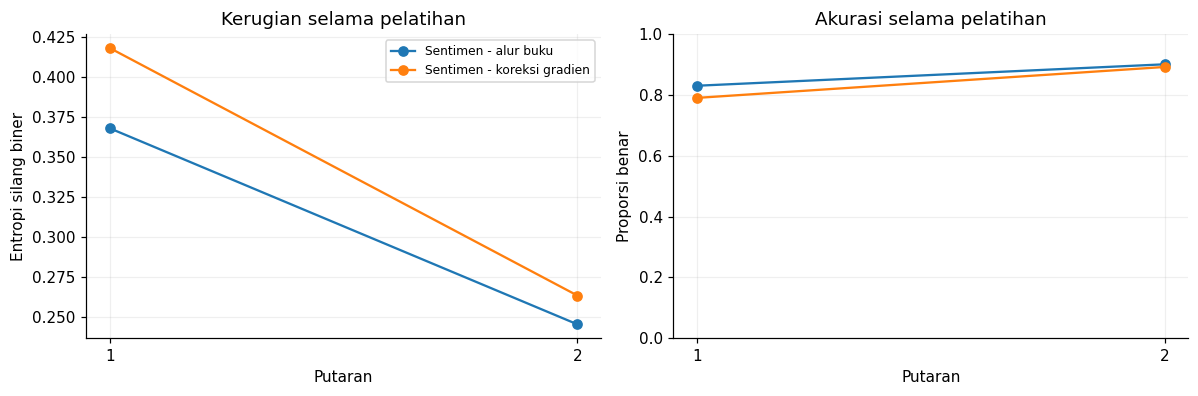

**Pembacaan hasil eksekusi ini.** Akurasi uji alur buku adalah **84.90%**, sedangkan versi koreksi adalah **85.30%**. Keduanya dievaluasi pada 1,000 ulasan yang sama. Koreksi gradien menjamin kesesuaian aturan rantai, tetapi tidak menjamin akurasi lebih tinggi pada laju pembelajaran dan jumlah putaran yang belum disetel ulang. Hasil ini merupakan evaluasi pemisahan sederhana buku dengan kamus transduktif.

In [10]:
gambar, sumbu = plt.subplots(1, 2, figsize=(11, 3.7))
for model in [model_sentimen_buku, model_sentimen_koreksi]:
    r = model["riwayat"]
    sumbu[0].plot(r["Putaran"], r["Kerugian latih"], marker="o", label=model["nama"])
    sumbu[1].plot(r["Putaran"], r["Akurasi latih berjalan"], marker="o", label=model["nama"])
sumbu[0].set(title="Kerugian selama pelatihan", xlabel="Putaran", ylabel="Entropi silang biner")
sumbu[1].set(title="Akurasi selama pelatihan", xlabel="Putaran", ylabel="Proporsi benar", ylim=(0, 1))
for ax in sumbu:
    ax.set_xticks(range(1, PUTARAN_SENTIMEN + 1))
    ax.grid(alpha=0.2)
sumbu[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Pembacaan hasil eksekusi ini.** Akurasi uji alur buku adalah "
    f"**{metrik_buku['Akurasi uji']:.2%}**, sedangkan versi koreksi adalah "
    f"**{metrik_koreksi['Akurasi uji']:.2%}**. Keduanya dievaluasi pada "
    f"{len(y_uji):,} ulasan yang sama. Koreksi gradien menjamin kesesuaian "
    "aturan rantai, tetapi tidak menjamin akurasi lebih tinggi pada laju "
    "pembelajaran dan jumlah putaran yang belum disetel ulang. Hasil ini "
    "merupakan evaluasi pemisahan sederhana buku dengan kamus transduktif."
))

## 10. Pengaruh arsitektur: informasi yang tidak dapat dipulihkan

Lapisan tersembunyi dapat mempelajari kombinasi ciri yang berguna bagi target. Namun, ia tidak dapat memulihkan urutan yang sudah dibuang oleh representasi masukan. Dua kalimat dengan himpunan kata identik akan mempunyai hasil penjumlahan baris, aktivasi tersembunyi, dan prediksi yang identik.

Contoh berikut memiliki kata yang sama, tetapi penempatan penyangkalannya berbeda. Masalahnya bukan sekadar kurang banyak neuron: seluruh model yang hanya menerima kantong kata yang sama akan kehilangan pembeda tersebut. Kantong kata tetap dapat menangkap sebagian pola kehadiran penyangkalan; keterbatasan yang dibuktikan di sini adalah ketidakmampuan membedakan susunan berbeda dengan kantong kata identik.

In [11]:
kalimat_a = "it was great not terrible"
kalimat_b = "it was terrible not great"

def indeks_teks_biner(teks):
    return np.asarray(sorted({kata_ke_indeks[k] for k in teks.lower().split()
                              if k in kata_ke_indeks}), dtype=np.int64)

ia, ib = indeks_teks_biner(kalimat_a), indeks_teks_biner(kalimat_b)
ha, _, pa = maju_sentimen(ia, model_sentimen_koreksi["E"], model_sentimen_koreksi["w"])
hb, _, pb = maju_sentimen(ib, model_sentimen_koreksi["E"], model_sentimen_koreksi["w"])
np.testing.assert_array_equal(ia, ib)
np.testing.assert_allclose(ha, hb)
print("Kalimat A:", kalimat_a)
print("Kalimat B:", kalimat_b)
print("Peluang positif A dan B:", round(pa, 6), round(pb, 6))
print("Kantong kata identik, sehingga kedua prediksi identik.")

Kalimat A: it was great not terrible
Kalimat B: it was terrible not great
Peluang positif A dan B: 0.308143 0.308143
Kantong kata identik, sehingga kedua prediksi identik.


## 11. Membandingkan representasi dan menjelaskan makna neuron

Untuk vektor $e_a$ dan $e_b$, buku menggunakan jarak Euklides:

$$d(e_a,e_b)=\sqrt{\sum_{j=1}^{d}(e_{a,j}-e_{b,j})^2}.$$

Semakin kecil jaraknya, semakin dekat kedua representasi. Fungsi buku menegatifkan jarak supaya nilai terbesar menjadi yang paling dekat. Implementasi berikut langsung mengurutkan jarak terkecil dan mengeluarkan kata pencarian dari kandidat.

Model sentimen menerima tekanan untuk membedakan label positif dan negatif. Karena itu, kata yang membantu prediksi label serupa dapat menjadi dekat, meskipun kelas kata atau makna kamusnya berbeda. Satu koordinat representasi tidak otomatis memiliki arti manusiawi tertentu. Informasi dapat tersebar pada banyak dimensi; penafsiran neuron sebagai kelompok adalah alat bantu pemahaman, bukan bukti setiap neuron memiliki satu arti tetap.

In [12]:
def tetangga_kata(kata, E, jumlah=8, kandidat=None, metrik="euklides"):
    if kata not in kata_ke_indeks:
        return pd.DataFrame({"Keterangan": [f"Kata {kata!r} tidak ada dalam kosakata."]})
    indeks = kata_ke_indeks[kata]
    tersedia = np.ones(len(kosakata), dtype=bool) if kandidat is None else kandidat.copy()
    tersedia[indeks] = False
    if metrik == "euklides":
        skor = np.linalg.norm(E - E[indeks], axis=1)
        skor[~tersedia] = np.inf
        urutan = np.argsort(skor)[:min(jumlah, int(tersedia.sum()))]
        nama_skor = "Jarak Euklides"
    elif metrik == "kosinus":
        norma = np.maximum(np.linalg.norm(E, axis=1), 1e-12)
        skor = (E @ E[indeks]) / (norma * norma[indeks])
        skor[~tersedia] = -np.inf
        urutan = np.argsort(-skor)[:min(jumlah, int(tersedia.sum()))]
        nama_skor = "Kemiripan kosinus"
    else:
        raise ValueError("Metrik tidak dikenali.")
    return pd.DataFrame({"Kata": [kosakata[i] for i in urutan],
                         nama_skor: skor[urutan]})

for kata in ["beautiful", "terrible"]:
    print("Tetangga representasi sentimen alur buku untuk:", kata)
    display(tetangga_kata(kata, model_sentimen_buku["E"]).round(4))

Tetangga representasi sentimen alur buku untuk: beautiful


,Kata,Jarak Euklides
0,sweet,0.6986
1,each,0.7010
2,bit,0.7042
3,masterpiece,0.7119
4,tight,0.7119
5,underrated,0.7164
6,ralph,0.7226
7,jack,0.7244


Tetangga representasi sentimen alur buku untuk: terrible


,Kata,Jarak Euklides
0,disappointment,0.7580
1,annoying,0.7637
2,boring,0.7778
3,poor,0.7817
4,avoid,0.7881
5,laughable,0.7917
6,bad,0.8200
7,dull,0.8209


## 12. Mengisi kata yang hilang: belajar dari konteks

Label sentimen memberikan sasaran yang cukup sempit. Untuk mempelajari hubungan yang lebih kaya, model diberi konteks lokal dan diminta mengenali kata pusat yang dihilangkan. Target kini diperoleh dari teks itu sendiri, sehingga tugas ini merupakan **pembelajaran swaawasi**. Pendekatannya mengikuti gagasan kantong kata berkelanjutan: rata-rata representasi kata konteks dipakai untuk memprediksi kata pusat.

Untuk konteks $C$ dan kata pusat $t$:

$$h=\frac{1}{|C|}\sum_{c\in C}E_c,\qquad s_w=U_w^\top h.$$

Matriks $E$ menyimpan vektor masukan dan matriks $U$ menyimpan vektor keluaran. Keduanya berbeda, masing-masing berukuran $V\times d$. Lapisan tersembunyi pada model konteks adalah **rata-rata linear tanpa sigmoid**. Kita menelusuri tetangga menggunakan $E$, sesuai buku.

**Jendela konteks.** Maksud jendela 2 adalah mengambil maksimal dua kata di kiri dan dua di kanan. Indeks akhir irisan Python tidak disertakan. Oleh sebab itu, batas kanan harus `posisi + JENDELA + 1`. Kode cetak berhenti pada `posisi + JENDELA`, sehingga hanya mengambil satu kata kanan ketika jendela bernilai 2. Kedua perilaku disediakan agar perbedaannya dapat dilihat.

In [13]:
def ambil_konteks(urutan, posisi, jendela=2, koreksi=True):
    tambahan = 1 if koreksi else 0
    kiri = urutan[max(0, posisi - jendela):posisi]
    kanan = urutan[posisi + 1:min(len(urutan), posisi + jendela + tambahan)]
    return np.concatenate([kiri, kanan])

contoh_urutan = np.arange(7)
print("Posisi pusat:", 3)
print("Konteks versi buku:", ambil_konteks(contoh_urutan, 3, 2, False))
print("Konteks simetris:", ambil_konteks(contoh_urutan, 3, 2, True))
np.testing.assert_array_equal(ambil_konteks(contoh_urutan, 3, 2, True), [1, 2, 4, 5])

pengacak_korpus = np.random.RandomState(BENIH)
pilihan_ulasan = pengacak_korpus.permutation(len(token_berurutan))
if BATAS_ULASAN_KONTEKS is not None:
    pilihan_ulasan = pilihan_ulasan[:BATAS_ULASAN_KONTEKS]
korpus_konteks = []
for nomor in pilihan_ulasan:
    kata_baris = token_berurutan[nomor]
    if BATAS_KATA_KONTEKS is not None:
        kata_baris = kata_baris[:BATAS_KATA_KONTEKS]
    if len(kata_baris) >= 2:
        korpus_konteks.append(np.asarray([kata_ke_indeks[k] for k in kata_baris],
                                        dtype=np.int64))
rangkaian_kata = np.concatenate(korpus_konteks)
frekuensi_konteks = np.bincount(rangkaian_kata, minlength=len(kosakata))
kandidat_konteks = frekuensi_konteks >= 5
print("Ulasan yang digunakan untuk konteks:", len(korpus_konteks))
print("Jumlah kemunculan kata dalam korpus konteks:", len(rangkaian_kata))
print("Perkiraan pembaruan per model:", len(rangkaian_kata) * PUTARAN_KONTEKS)
print("Kata dengan sedikitnya 5 kemunculan:", int(kandidat_konteks.sum()))
print("Pengulangan kata dipertahankan; label sentimen tidak digunakan.")

Posisi pusat: 3
Konteks versi buku: [1 2 4]
Konteks simetris: [1 2 4 5]
Ulasan yang digunakan untuk konteks: 3000
Jumlah kemunculan kata dalam korpus konteks: 342460
Perkiraan pembaruan per model: 684920
Kata dengan sedikitnya 5 kemunculan: 5073
Pengulangan kata dipertahankan; label sentimen tidak digunakan.


## 13. Pengambilan sampel negatif dan fungsi kerugian

Softmax penuh akan menghitung skor seluruh kosakata untuk setiap kata pusat. Dengan puluhan ribu kata, langkah itu mahal. Pengambilan sampel negatif mengganti sasaran tersebut dengan beberapa keputusan biner: pasangan konteks-kata pusat diberi target 1, sedangkan $K$ kata acak diberi target 0.

$$\mathcal L=-\log\sigma(s_t)-\sum_{k=1}^{K}\log\sigma(-s_{n_k}).$$

Jika $S=[t,n_1,\ldots,n_K]$ dan $y=[1,0,\ldots,0]$, maka:

$$\delta_j=\sigma(U_{S_j}^\top h)-y_j,$$
$$\frac{\partial\mathcal L}{\partial U_{S_j}}=\delta_j h,\qquad
\frac{\partial\mathcal L}{\partial h}=\sum_j\delta_j U_{S_j},$$
$$\frac{\partial\mathcal L}{\partial E_c}=\frac{1}{|C|}\frac{\partial\mathcal L}{\partial h}
\quad\text{untuk setiap kemunculan }c\in C.$$

Jika kata yang sama muncul beberapa kali dalam konteks atau sampel keluaran, kontribusi gradiennya harus **dijumlahkan**. `np.add.at` menangani pengulangan indeks; pembaruan melalui indeks lanjut dengan `-=` dapat kehilangan akumulasi tersebut.

Sampel negatif diambil dari rangkaian kata, sehingga peluang dasar sebuah kata sebanding dengan frekuensinya, seperti kode buku. Notebook tidak menggunakan pemangkatan frekuensi 0,75 atau pembuangan kata sangat sering. Pada versi koreksi, sampel yang sama dengan kata pusat diambil ulang agar tidak menerima label positif dan negatif pada langkah yang sama. Sampel negatif tetap boleh berulang satu sama lain.

Pengambilan sampel negatif mempunyai tujuan biner tersendiri; keluarannya tidak membentuk distribusi softmax penuh yang jumlahnya 1. Biaya skor keluaran turun dari sekitar $O(Vd)$ menjadi $O((K+1)d)$, di luar biaya pembentukan konteks. Matriks model tetap membutuhkan ruang $O(Vd)$.

### 13.1 Memeriksa gradien model konteks dengan indeks berulang

Kasus kecil berikut sengaja memuat kata konteks dan sampel negatif yang berulang. Pemeriksaan mencakup seluruh elemen matriks kecil, sehingga kesalahan pembagian rata-rata atau akumulasi indeks dapat terdeteksi.

In [14]:
def rugi_dan_gradien_konteks(E, U, konteks, sampel):
    h = E[konteks].mean(axis=0)
    target = np.zeros(len(sampel))
    target[0] = 1
    logit = U[sampel] @ h
    delta = sigmoid(logit) - target
    rugi = float(kerugian_biner_logit(logit, target).sum())
    gE, gU = np.zeros_like(E), np.zeros_like(U)
    gradien_h = delta @ U[sampel]
    np.add.at(gE, konteks, gradien_h / len(konteks))
    np.add.at(gU, sampel, delta[:, None] * h[None, :])
    return rugi, gE, gU

acak_kecil = np.random.RandomState(11)
E_kecil = acak_kecil.normal(0, 0.2, (4, 3))
U_kecil = acak_kecil.normal(0, 0.2, (4, 3))
konteks_kecil = np.array([0, 1, 0])
sampel_kecil = np.array([2, 3, 3])
_, gE_kecil, gU_kecil = rugi_dan_gradien_konteks(
    E_kecil, U_kecil, konteks_kecil, sampel_kecil)

def numerik_seluruh_matriks(matriks):
    hasil = np.zeros_like(matriks)
    epsilon = 1e-6
    for posisi in np.ndindex(matriks.shape):
        awal = matriks[posisi]
        matriks[posisi] = awal + epsilon
        plus = rugi_dan_gradien_konteks(E_kecil, U_kecil, konteks_kecil, sampel_kecil)[0]
        matriks[posisi] = awal - epsilon
        minus = rugi_dan_gradien_konteks(E_kecil, U_kecil, konteks_kecil, sampel_kecil)[0]
        matriks[posisi] = awal
        hasil[posisi] = (plus - minus) / (2 * epsilon)
    return hasil

numerik_E_konteks = numerik_seluruh_matriks(E_kecil)
numerik_U_konteks = numerik_seluruh_matriks(U_kecil)
np.testing.assert_allclose(gE_kecil, numerik_E_konteks, rtol=1e-5, atol=1e-8)
np.testing.assert_allclose(gU_kecil, numerik_U_konteks, rtol=1e-5, atol=1e-8)
print("Selisih maksimum gradien E:", float(np.max(np.abs(gE_kecil - numerik_E_konteks))))
print("Selisih maksimum gradien U:", float(np.max(np.abs(gU_kecil - numerik_U_konteks))))
print("Pemeriksaan gradien konteks dengan indeks berulang: lulus.")

Selisih maksimum gradien E: 3.937955517230307e-10
Selisih maksimum gradien U: 2.340899002417629e-10
Pemeriksaan gradien konteks dengan indeks berulang: lulus.


## 14. Reproduksi pelatihan kata dari konteks

Kedua versi menggunakan dimensi 50, jendela nominal 2, lima sampel negatif, laju pembelajaran 0,05, dan dua putaran. Matriks masukan diinisialisasi acak, sedangkan matriks keluaran dimulai dari nol, mengikuti buku. Pada langkah pertama, gradien menuju matriks masukan memang nol karena bobot keluaran masih nol; bobot keluaran diperbarui terlebih dahulu melalui gradiennya sendiri, lalu matriks masukan dapat belajar pada langkah berikutnya.

| Komponen | Alur buku | Versi koreksi |
|---|---|---|
| Agregasi konteks | Rata-rata | Rata-rata |
| Jendela kanan, ukuran 2 | Satu kata | Dua kata |
| Turunan rata-rata | Tidak dibagi banyak konteks | Dibagi banyak konteks |
| Indeks berulang | Pembaruan indeks lanjut seperti buku | Akumulasi dengan `np.add.at` |
| Negatif sama dengan pusat | Dapat terjadi | Diambil ulang |

Versi koreksi mengubah beberapa hal sekaligus, sehingga perbedaan hasilnya **tidak dapat diatribusikan kepada satu perubahan saja**. Tujuan perbandingannya adalah memahami implementasi, bukan mengklaim percobaan penyebab tunggal. Dalam mode praktis, kedua versi memakai potongan korpus yang sama dan urutan ulasan yang sama.

In [15]:
def latih_konteks(koreksi, judul):
    pengacak = np.random.RandomState(BENIH)
    E = pengacak.uniform(-0.1, 0.1, (len(kosakata), DIMENSI_KONTEKS))
    U = np.zeros_like(E)
    target = np.zeros(JUMLAH_NEGATIF + 1)
    target[0] = 1
    riwayat = []
    mulai = time.perf_counter()
    for putaran in range(PUTARAN_KONTEKS):
        jumlah_rugi, jumlah_langkah = 0.0, 0
        for nomor, urutan in enumerate(korpus_konteks):
            # Penarikan dari kemunculan kata menghasilkan distribusi frekuensi.
            negatif_baris = rangkaian_kata[pengacak.randint(
                len(rangkaian_kata), size=(len(urutan), JUMLAH_NEGATIF))]
            if koreksi:
                bertabrakan = negatif_baris == urutan[:, None]
                while bertabrakan.any():
                    negatif_baris[bertabrakan] = rangkaian_kata[pengacak.randint(
                        len(rangkaian_kata), size=int(bertabrakan.sum()))]
                    bertabrakan = negatif_baris == urutan[:, None]
            for posisi, pusat in enumerate(urutan):
                konteks = ambil_konteks(urutan, posisi, JENDELA, koreksi)
                if len(konteks) == 0:
                    continue
                sampel = np.concatenate(([pusat], negatif_baris[posisi]))
                h = E[konteks].mean(axis=0)
                # Simpan bobot lama agar gradien kedua matriks konsisten.
                U_terpilih = U[sampel].copy()
                logit = U_terpilih @ h
                delta = sigmoid(logit) - target
                gradien_h = delta @ U_terpilih
                if koreksi:
                    np.add.at(E, konteks, -LAJU_KONTEKS * gradien_h / len(konteks))
                    np.add.at(U, sampel, -LAJU_KONTEKS * delta[:, None] * h[None, :])
                else:
                    # Ini sengaja mempertahankan pembaruan pada halaman 202.
                    E[konteks] -= LAJU_KONTEKS * gradien_h
                    U[sampel] -= LAJU_KONTEKS * delta[:, None] * h[None, :]
                jumlah_rugi += float(kerugian_biner_logit(logit, target).sum())
                jumlah_langkah += 1
            if (nomor + 1) % 1000 == 0:
                print(f"{judul} | Putaran {putaran+1}: "
                      f"{nomor+1}/{len(korpus_konteks)} ulasan selesai")
        riwayat.append({"Putaran": putaran + 1,
                        "Kerugian per kata pusat": jumlah_rugi / jumlah_langkah,
                        "Jumlah pembaruan": jumlah_langkah})
        print(f"{judul} | Rugi rata-rata putaran {putaran+1}: "
              f"{riwayat[-1]['Kerugian per kata pusat']:.4f}")
    assert np.isfinite(E).all() and np.isfinite(U).all(), "Bobot tidak berhingga."
    return {"E": E, "U": U, "riwayat": pd.DataFrame(riwayat),
            "durasi": time.perf_counter() - mulai, "nama": judul}

In [16]:
model_konteks_buku = latih_konteks(False, "Konteks - alur buku")
model_konteks_koreksi = latih_konteks(True, "Konteks - koreksi")
display(model_konteks_buku["riwayat"].round(4))
display(model_konteks_koreksi["riwayat"].round(4))

Konteks - alur buku | Putaran 1: 1000/3000 ulasan selesai
Konteks - alur buku | Putaran 1: 2000/3000 ulasan selesai
Konteks - alur buku | Putaran 1: 3000/3000 ulasan selesai
Konteks - alur buku | Rugi rata-rata putaran 1: 2.5839
Konteks - alur buku | Putaran 2: 1000/3000 ulasan selesai
Konteks - alur buku | Putaran 2: 2000/3000 ulasan selesai
Konteks - alur buku | Putaran 2: 3000/3000 ulasan selesai
Konteks - alur buku | Rugi rata-rata putaran 2: 2.2234
Konteks - koreksi | Putaran 1: 1000/3000 ulasan selesai
Konteks - koreksi | Putaran 1: 2000/3000 ulasan selesai
Konteks - koreksi | Putaran 1: 3000/3000 ulasan selesai
Konteks - koreksi | Rugi rata-rata putaran 1: 2.6859
Konteks - koreksi | Putaran 2: 1000/3000 ulasan selesai
Konteks - koreksi | Putaran 2: 2000/3000 ulasan selesai
Konteks - koreksi | Putaran 2: 3000/3000 ulasan selesai
Konteks - koreksi | Rugi rata-rata putaran 2: 2.3103


,Putaran,Kerugian per kata pusat,Jumlah pembaruan
0,1,2.5839,342460
1,2,2.2234,342460


,Putaran,Kerugian per kata pusat,Jumlah pembaruan
0,1,2.6859,342460
1,2,2.3103,342460


### 14.1 Mencoba kata yang dihilangkan

Masukan contoh berikut berisi kata-kata di sekitar bagian yang kosong pada pola `this movie ___ very good`. Model memberi skor kata kandidat menggunakan matriks keluaran $U$. Skor logit dipakai untuk mengurutkan kandidat; sigmoidnya adalah skor biner yang dipelajari terhadap sampel negatif, **bukan peluang kata lengkap yang ternormalisasi**.

Pengujian ini bersifat kualitatif. Korpus yang dibatasi dan tugas pengambilan sampel negatif tidak menjamin satu kata yang paling wajar menurut manusia berada di urutan pertama. Nilai kerugian latih juga bukan ukuran akurasi pengisian kata pada data baru.

In [17]:
def calon_kata_hilang(teks_konteks, model, jumlah=10):
    kata_konteks = teks_konteks.lower().split()
    hilang = [k for k in kata_konteks if k not in kata_ke_indeks]
    if hilang:
        raise ValueError("Kata di luar kosakata: " + ", ".join(hilang))
    indeks = np.asarray([kata_ke_indeks[k] for k in kata_konteks])
    if len(indeks) == 0:
        raise ValueError("Konteks harus memuat setidaknya satu kata.")
    h = model["E"][indeks].mean(axis=0)
    skor = model["U"] @ h
    skor[~kandidat_konteks] = -np.inf
    urutan = np.argsort(-skor)[:jumlah]
    return pd.DataFrame({"Kandidat kata": [kosakata[i] for i in urutan],
                         "Skor logit": skor[urutan],
                         "Skor sigmoid biner": sigmoid(skor[urutan])})

print("Pola: this movie ___ very good")
display(calon_kata_hilang("this movie very good", model_konteks_koreksi).round(4))

Pola: this movie ___ very good


,Kandidat kata,Skor logit,Skor sigmoid biner
0,is,2.6248,0.9324
1,a,1.4842,0.8152
2,was,1.1267,0.7552
3,makes,1.0631,0.7433
4,looks,0.4566,0.6122
5,short,0.3458,0.5856
6,very,0.3353,0.5830
7,does,0.2731,0.5678
8,watching,0.1764,0.5440
9,than,0.0711,0.5178


## 15. Mengapa tujuan pembelajaran menentukan makna representasi?

Pada model sentimen, targetnya positif atau negatif. Pada model konteks, targetnya adalah kehadiran suatu kata pada konteks tertentu dibandingkan kata acak. Karena gradien berasal dari target yang berbeda, hubungan yang ditekankan dalam bobot juga berbeda.

Kata berlawanan sentimen dapat memiliki konteks yang serupa, misalnya sama-sama muncul setelah keterangan atau sebelum kata `movie`. Maka representasi konteks dapat menempatkan kata positif dan negatif berdekatan. Kedekatan ini menunjukkan kemiripan penggunaan, bukan persetujuan bahwa keduanya bersinonim.

Dalam pengertian optimisasi, model meminimalkan kerugian sebagai fungsi parameter. Sasaran itu ditentukan bersama oleh data dan target, komputasi model, ukuran lapisan, fungsi aktivasi, bentuk pengukuran kesalahan, serta regularisasi jika digunakan. Tidak semua pilihan arsitektur disebut fungsi kerugian dalam pengertian sempit, tetapi semuanya mengubah pemetaan parameter ke nilai objektif yang dioptimalkan.

Tabel berikut memakai kata kandidat yang muncul sedikitnya lima kali dalam korpus konteks, supaya kata yang tidak terlatih atau sangat jarang tidak mendominasi penelusuran. Pembatasan ini merupakan bantuan analisis; fungsi pada bagian 11 tetap dapat mereproduksi pencarian pada seluruh kosakata. Kedekatan semantik juga dipengaruhi cakupan korpus, jumlah putaran, dan banyaknya kemunculan kata.

In [18]:
baris_perbandingan = []
for kata in ["terrible", "beautiful", "movie"]:
    for nama, E in [
        ("Sentimen: alur buku", model_sentimen_buku["E"]),
        ("Konteks: alur buku", model_konteks_buku["E"]),
        ("Konteks: koreksi", model_konteks_koreksi["E"]),
    ]:
        tabel = tetangga_kata(kata, E, jumlah=8, kandidat=kandidat_konteks)
        baris_perbandingan.append({"Kata acuan": kata, "Model": nama,
                                    "Delapan tetangga": ", ".join(tabel["Kata"])})
display(pd.DataFrame(baris_perbandingan))

,Kata acuan,Model,Delapan tetangga
0,terrible,Sentimen: alur buku,"disappointment, annoying, boring, poor, avoid,..."
1,terrible,Konteks: alur buku,"cool, superb, fantastic, ridiculous, hilarious..."
2,terrible,Konteks: koreksi,"ok, true, superb, hilarious, cool, awful, horr..."
3,beautiful,Sentimen: alur buku,"sweet, each, bit, masterpiece, tight, underrat..."
4,beautiful,Konteks: alur buku,"superb, fantastic, delightful, bizarre, fantas..."
5,beautiful,Konteks: koreksi,"complete, brilliant, french, dark, fantastic, ..."
6,movie,Sentimen: alur buku,"lampoon, flower, be, lightweight, not, do, bom..."
7,movie,Konteks: alur buku,"film, show, thing, series, flick, script, pict..."
8,movie,Konteks: koreksi,"film, show, story, series, thing, flick, scrip..."


### 15.1 Visualisasi dua dimensi sebagai alat bantu

Analisis komponen utama memusatkan matriks vektor lalu memilih dua arah dengan variasi terbesar. Kode berikut menghitungnya dengan dekomposisi nilai singular NumPy. Ini adalah tambahan analisis, bukan tahap pelatihan pada buku.

Proyeksi membuang banyak informasi. Jarak pada grafik tidak sama persis dengan jarak pada ruang 50 dimensi, dan dua sumbu gambar tidak diberi arti seperti sentimen atau gender secara otomatis. Gunakan daftar tetangga di ruang asli untuk mendampingi pembacaan grafik.

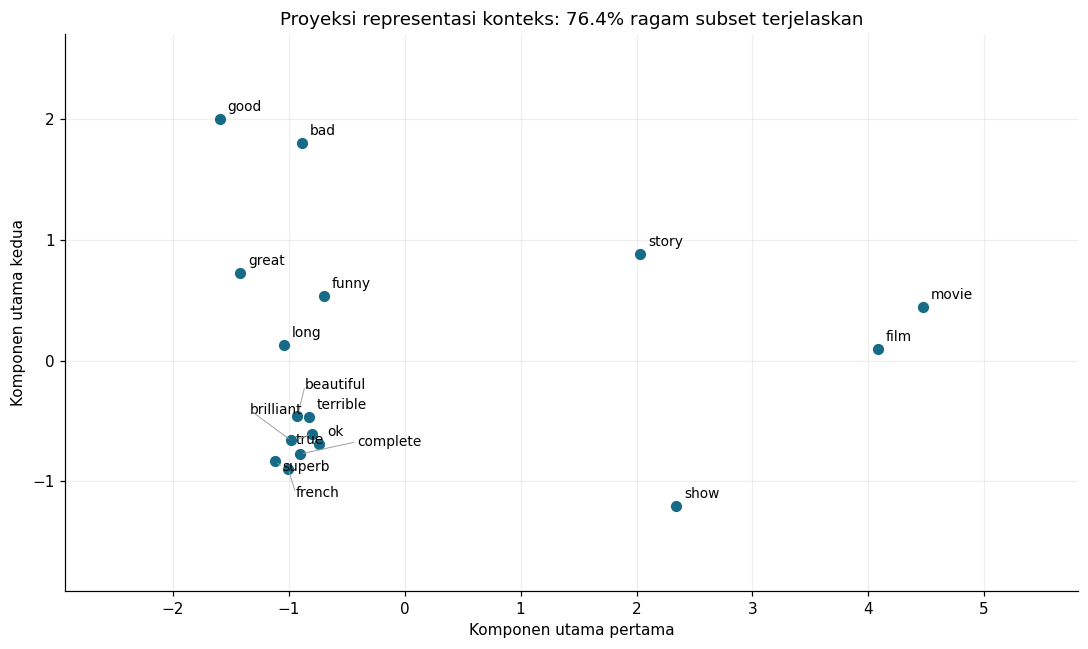

In [19]:
kata_gambar = []
for kata in ["terrible", "beautiful", "movie", "good", "bad"]:
    if kata in kata_ke_indeks:
        kata_gambar.append(kata)
        kata_gambar.extend(tetangga_kata(
            kata, model_konteks_koreksi["E"], jumlah=3,
            kandidat=kandidat_konteks)["Kata"].tolist())
kata_gambar = list(dict.fromkeys(kata_gambar))
vektor_gambar = model_konteks_koreksi["E"][[kata_ke_indeks[k] for k in kata_gambar]]
vektor_terpusat = vektor_gambar - vektor_gambar.mean(axis=0)
_, nilai_singular, arah = np.linalg.svd(vektor_terpusat, full_matrices=False)
koordinat = vektor_terpusat @ arah[:2].T
ragam_terjelaskan = (nilai_singular[:2] ** 2).sum() / (nilai_singular ** 2).sum()

gambar, ax = plt.subplots(figsize=(10, 6))
ax.scatter(koordinat[:, 0], koordinat[:, 1], s=40, color="#176b87", zorder=3)
ax.set(title=f"Proyeksi representasi konteks: {ragam_terjelaskan:.1%} ragam subset terjelaskan",
       xlabel="Komponen utama pertama", ylabel="Komponen utama kedua")
ax.grid(alpha=0.2)
ax.margins(0.22)
gambar.tight_layout()
gambar.canvas.draw()

# Geser label ke tempat terdekat yang belum terisi agar kata tetap terbaca.
perender = gambar.canvas.get_renderer()
kotak_terpakai = []
pilihan_geser = sorted([(dx, dy) for dx in range(-96, 97, 16)
                        for dy in range(-72, 73, 12)],
                       key=lambda p: p[0] ** 2 + p[1] ** 2)
for kata, (x, y) in zip(kata_gambar, koordinat):
    tulisan = ax.annotate(kata, (x, y), xytext=(5, 8),
                         textcoords="offset points", fontsize=9, va="center")
    for dx, dy in pilihan_geser:
        tulisan.set_position((dx + 5, dy + 8))
        kotak = tulisan.get_window_extent(perender).expanded(1.06, 1.18)
        di_dalam = (ax.bbox.contains(kotak.x0, kotak.y0)
                    and ax.bbox.contains(kotak.x1, kotak.y1))
        if di_dalam and not any(kotak.overlaps(k) for k in kotak_terpakai):
            break
    kotak_terpakai.append(kotak)
    if abs(dx) + abs(dy) > 0:
        ax.annotate("", (x, y), xytext=(dx + 5, dy + 8),
                    textcoords="offset points",
                    arrowprops={"arrowstyle": "-", "color": "0.6", "lw": 0.6})
plt.show()

## 16. Analogi kata dan aritmetika vektor

Analogi membentuk vektor pertanyaan $q=e_{king}-e_{man}+e_{woman}$, kemudian mencari kata yang paling dekat dengan $q$. Intuisinya, beberapa hubungan penggunaan kata dapat tampak sebagai arah yang mendekati sejajar pada ruang representasi. Pola itu berasal dari statistik kemunculan bersama dan tujuan pelatihan, bukan aturan bahasa yang secara eksplisit diprogramkan.

Pada ilustrasi, dimensi dapat dibayangkan memisahkan beberapa ciri. Dalam model nyata, ciri biasanya tersebar dan sumbu tidak harus selaras dengan konsep manusia. Pada model konteks linear, rotasi ortogonal yang sama pada $E$ dan $U$ mempertahankan hasil kali titiknya; karena itu nama arti yang dilekatkan pada satu koordinat bukan sesuatu yang unik.

Contoh angka dua dimensi di bawah berasal dari ilustrasi halaman 207. Angka ini **ditentukan untuk menjelaskan geometri**, bukan dihasilkan oleh pelatihan IMDB. Hasilnya mendekati ratu, tidak sama persis.

In [20]:
vektor_ilustrasi = {
    "king": np.array([0.6, 0.1]),
    "man": np.array([0.5, 0.0]),
    "woman": np.array([0.0, 0.8]),
    "queen": np.array([0.1, 1.0]),
}
pertanyaan_ilustrasi = (vektor_ilustrasi["king"] - vektor_ilustrasi["man"]
                       + vektor_ilustrasi["woman"])
print("Vektor raja - pria + wanita:", pertanyaan_ilustrasi)
print("Vektor ratu pada ilustrasi:", vektor_ilustrasi["queen"])
print("Jarak ke ratu:", np.linalg.norm(pertanyaan_ilustrasi - vektor_ilustrasi["queen"]))

Vektor raja - pria + wanita: [0.1 0.9]
Vektor ratu pada ilustrasi: [0.1 1. ]
Jarak ke ratu: 0.09999999999999998


### 16.1 Mereproduksi perhitungan analogi buku

Kode halaman 206 menghitung jumlah kuadrat setiap baris, lalu **mengalikan** representasi dengan nilai itu saat membentuk pertanyaan. Operasi tersebut bukan normalisasi panjang vektor. Setelah itu, pertanyaan berskala tadi dibandingkan dengan representasi asli dan hanya kandidat pertama yang dibuang. Membuang satu kandidat pertama tidak menjamin seluruh kata penyusun pertanyaan ikut dikeluarkan.

Fungsi berikut sengaja mempertahankan perhitungan tersebut untuk keperluan reproduksi. Hasilnya ditampilkan sebagai hasil aturan buku, bukan dianggap implementasi kemiripan kosinus yang benar.

In [21]:
def analogi_versi_buku(positif, negatif, E, jumlah=8):
    tidak_ada = [k for k in positif + negatif if k not in kata_ke_indeks]
    if tidak_ada:
        return pd.DataFrame({"Keterangan": ["Kata tidak tersedia: " + ", ".join(tidak_ada)]})
    norma_kuadrat = np.sum(E * E, axis=1, keepdims=True)
    berskala = E * norma_kuadrat
    q = np.zeros(E.shape[1])
    for kata in positif:
        q += berskala[kata_ke_indeks[kata]]
    for kata in negatif:
        q -= berskala[kata_ke_indeks[kata]]
    jarak = np.linalg.norm(E - q, axis=1)
    # Persis gagasan membuang kandidat pertama pada contoh buku.
    urutan = np.argsort(jarak)[:jumlah + 1][1:]
    return pd.DataFrame({"Kata": [kosakata[i] for i in urutan],
                         "Skor negatif jarak, versi buku": -jarak[urutan]})

print("Aturan buku: terrible - bad + good")
display(analogi_versi_buku(["terrible", "good"], ["bad"], model_konteks_buku["E"]).round(4))
print("Aturan buku: elizabeth - she + he")
display(analogi_versi_buku(["elizabeth", "he"], ["she"], model_konteks_buku["E"]).round(4))

Aturan buku: terrible - bad + good


,Kata,"Skor negatif jarak, versi buku"
0,good,-144.1858
1,well,-144.9757
2,very,-145.2047
3,their,-145.3381
4,its,-145.3768
5,great,-145.6112
6,his,-145.6468
7,the,-145.7075


Aturan buku: elizabeth - she + he


,Kata,"Skor negatif jarak, versi buku"
0,my,-192.8621
1,no,-192.9968
2,his,-193.0901
3,doesn,-193.1037
4,other,-193.1355
5,that,-193.1775
6,any,-193.1943
7,where,-193.3148


### 16.2 Analogi dengan normalisasi dan pengecualian kata pertanyaan

Kemiripan kosinus mengukur arah:

$$\operatorname{cos}(a,b)=\frac{a^\top b}{\|a\|_2\|b\|_2}.$$

Versi tambahan berikut menormalisasi setiap baris dengan **membagi** norma L2, menyusun pertanyaan dari vektor yang sudah dinormalisasi, lalu menormalisasi pertanyaannya. Seluruh kata pertanyaan dikeluarkan secara eksplisit. Pada vektor satuan, urutan kosinus setara dengan kebalikan urutan jarak Euklides karena $\|a-b\|^2=2-2\operatorname{cos}(a,b)$.

Implementasi ini adalah salah satu konvensi analogi yang konsisten; bukan salinan persis aturan skala pada buku. Keberhasilan `king - man + woman` tidak dijamin pada ulasan film, khususnya ketika memakai korpus praktis. Satu analogi juga belum cukup untuk membuktikan pemahaman bahasa secara umum.

In [22]:
def analogi_kosinus(positif, negatif, E, jumlah=8):
    semua_kata = positif + negatif
    tidak_ada = [k for k in semua_kata if k not in kata_ke_indeks]
    if tidak_ada:
        return pd.DataFrame({"Keterangan": ["Kata tidak tersedia: " + ", ".join(tidak_ada)]})
    belum_terlatih = [k for k in semua_kata if frekuensi_konteks[kata_ke_indeks[k]] == 0]
    if belum_terlatih:
        return pd.DataFrame({"Keterangan": ["Kata tidak muncul pada korpus konteks: "
                                              + ", ".join(belum_terlatih)]})
    norma = np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-12)
    normal = E / norma
    q = np.zeros(E.shape[1])
    for kata in positif:
        q += normal[kata_ke_indeks[kata]]
    for kata in negatif:
        q -= normal[kata_ke_indeks[kata]]
    if np.linalg.norm(q) < 1e-12:
        raise ValueError("Vektor pertanyaan nol; gunakan kombinasi kata lain.")
    q /= np.linalg.norm(q)
    skor = normal @ q
    tersedia = kandidat_konteks.copy()
    tersedia[[kata_ke_indeks[k] for k in semua_kata]] = False
    skor[~tersedia] = -np.inf
    urutan = np.argsort(-skor)[:min(jumlah, int(tersedia.sum()))]
    assert not (set(semua_kata) & {kosakata[i] for i in urutan})
    return pd.DataFrame({"Kata": [kosakata[i] for i in urutan],
                         "Kemiripan kosinus": skor[urutan]})

hasil_analogi = {}
for nama, positif, negatif in [
    ("terrible - bad + good", ["terrible", "good"], ["bad"]),
    ("elizabeth - she + he", ["elizabeth", "he"], ["she"]),
    ("king - man + woman", ["king", "woman"], ["man"]),
]:
    print("Analogi kosinus:", nama)
    hasil_analogi[nama] = analogi_kosinus(positif, negatif, model_konteks_koreksi["E"])
    display(hasil_analogi[nama].round(4))

Analogi kosinus: terrible - bad + good


,Kata,Kemiripan kosinus
0,superb,0.7412
1,laughable,0.7255
2,terrific,0.6979
3,brilliant,0.6972
4,true,0.6951
5,great,0.6897
6,cool,0.6847
7,shot,0.6813


Analogi kosinus: elizabeth - she + he


,Kata,Kemiripan kosinus
0,powell,0.8267
1,jack,0.8257
2,john,0.8192
3,supporting,0.8130
4,sean,0.8041
5,sam,0.8025
6,pushing,0.8017
7,martin,0.8012


Analogi kosinus: king - man + woman


,Kata,Kemiripan kosinus
0,sexual,0.8695
1,famous,0.8564
2,human,0.8471
3,grand,0.8241
4,wild,0.8204
5,treatment,0.8163
6,modern,0.8062
7,culture,0.7966


## 17. Ringkasan hasil, keterbatasan, dan pembahasan

**Temuan konseptual.** Representasi satu aktif menyatakan identitas kata, sedangkan representasi vektor padat dipelajari sebagai bobot model. Pemilihan baris matriks setara dengan perkalian masukan jarang, tetapi lebih hemat. Sasaran sentimen menekankan informasi yang membantu klasifikasi dua label; sasaran konteks menekankan pola penggunaan kata. Karena itu, tetangga dekat tidak selalu berarti sinonim.

**Temuan implementasi.** Model sentimen memerlukan turunan sigmoid tersembunyi untuk menjadi gradien tepat. Model konteks yang memakai rata-rata memerlukan pembagian gradien oleh jumlah konteks. Indeks yang berulang memerlukan akumulasi. Normalisasi untuk kemiripan kosinus harus membagi norma, dan kata-kata penyusun pertanyaan analogi harus dikeluarkan secara eksplisit.

**Batas hasil.** Kamus dibentuk dari seluruh ulasan seperti buku, sehingga evaluasinya belum sepenuhnya terpisah dari teks uji. Mode praktis mengurangi korpus konteks; kata jarang lebih sulit dipelajari dan hasil analogi dapat lemah. Keluaran kualitatif bukan bukti kemampuan memahami negasi, ironi, atau fakta dunia. Proyeksi dua dimensi juga tidak menggambarkan seluruh geometri representasi.

**Pengembangan yang dapat dilakukan.** Bangun kamus hanya dari data latih dengan token khusus untuk kata yang tidak dikenal; sediakan validasi untuk memilih parameter tanpa melihat label uji; gunakan pembagian data yang lebih representatif; ukur mutu pengisian kata pada korpus terpisah; dan lakukan beberapa pengulangan dengan benih berbeda. Untuk mengukur pengaruh satu koreksi secara khusus, ubah hanya satu komponen pada setiap percobaan.

Sel berikut merangkum hasil yang benar-benar dihitung pada eksekusi ini. Angka contoh dalam buku tidak disalin sebagai hasil notebook.

In [23]:
rekap_model = []
for model in [model_sentimen_buku, model_sentimen_koreksi,
              model_konteks_buku, model_konteks_koreksi]:
    rekap_model.append({"Model": model["nama"],
                        "Dimensi vektor": model["E"].shape[1],
                        "Putaran": len(model["riwayat"]),
                        "Waktu pelatihan (detik)": round(model["durasi"], 2)})
display(pd.DataFrame(rekap_model))
display(Markdown(
    f"Pada mode **{MODE_KORPUS}**, kedua model konteks menggunakan "
    f"**{len(korpus_konteks):,} ulasan** dan **{len(rangkaian_kata):,} kemunculan kata** "
    f"per putaran. Akurasi uji sentimen versi koreksi adalah "
    f"**{metrik_koreksi['Akurasi uji']:.2%}** dengan F1 positif "
    f"**{metrik_koreksi['F1 positif']:.4f}**. Penilaian daftar tetangga dan analogi "
    "harus merujuk pada tabel hasil aktual di atas; hasil ratu tidak dipaksakan."
))

,Model,Dimensi vektor,Putaran,Waktu pelatihan (detik)
0,Sentimen - alur buku,100,2,5.32
1,Sentimen - koreksi gradien,100,2,5.63
2,Konteks - alur buku,50,2,49.31
3,Konteks - koreksi,50,2,53.30


Pada mode **praktis**, kedua model konteks menggunakan **3,000 ulasan** dan **342,460 kemunculan kata** per putaran. Akurasi uji sentimen versi koreksi adalah **85.30%** dengan F1 positif **0.8486**. Penilaian daftar tetangga dan analogi harus merujuk pada tabel hasil aktual di atas; hasil ratu tidak dipaksakan.